#데이터에서 패턴 찾기(아이스크림 데이터 파일 활용)
1년(365일) 동안의 기온과 아이스크림 판매 수익 데이터를 파일에서 불러와 데이터 시각화 및 예측 모델 만들기

### 1. 드라이브 마운트
- Google Colab 환경에서 Google 드라이브를 마운트
- Colab에서 드라이브에 저장한 파일을 쓰려면 먼저 드라이브를 연결(마운트)한다.


방법 1
- Google Colab 환경에서 Google 드라이브를 마운트하는 데 사용
- 왼쪽 메뉴 중 '폴더' 모양 선택 - 히든 메뉴 나타나면 다시 '폴더(구글드라이브)' 모양 선택

방법 2

In [1]:
from google.colab import drive
# google.colab 모듈에서 drive 객체를 가져온다.
# drive는 Colab과 Google 드라이브를 연동해 주는 도구이다.

drive.mount('/content/drive/')
# /content/drive/ 경로에 드라이브가 연결되어 드라이브 안의 파일을 읽고 쓸 수 있다.
# 실행하면 인증 절차가 나타나고, 인증을 마치면 마운트된다.

Mounted at /content/drive/


드라이브 연결 후, 코드 파일(.ipynb)과 데이터 파일이 있는 경로로 이동

In [2]:
cd /content/drive/MyDrive/Colab Notebooks

/content/drive/MyDrive/Colab Notebooks


파일 목록 확인

In [3]:
ls

 07_9_사용자_정의_함수_1_25101171_샤프린.ipynb   icecream.csv      Week7.ipynb
'09_12_자동차 데이터 시각화_Colab.ipynb'         Untitled0.ipynb
 10_13_데이터_파일_활용.ipynb                    Untitled1.ipynb


### 2. 파일 읽기: np.loadtxt()
- 텍스트 파일에서 데이터를 읽어올 때 사용 (일반적으로 숫자 데이터)
- 파일 형식: 텍스트 파일 (CSV, 공백 구분 등)
- 반환값: 넘파이 배열
- delimiter: 데이터를 구분하는 기호를 지정한다.
- skiprows: 맨 위에서부터 지정한 줄 수만큼 건너뛰고 읽는다.


In [4]:
import numpy as np
data = np.loadtxt("icecream.csv", delimiter=",", skiprows=1)

#파일 출처: https://www.kaggle.com/datasets/raphaelmanayon/temperature-and-ice-cream-sales
#delimiter=',' : 데이터를 콤마(,)로 구분된 텍스트 파일(CSV)에서 데이터를 읽어올 때 사용
#skiprows=1 : 파일의 맨 위 1줄(헤더)을 건너뛰고 데이터를 읽어옴. 첫 번째 행(['Temperature', 'Ice Cream Profits']) 건너뜀.

### 3. 데이터 확인 및 전처리
모델에 넣기 전에 데이터를 쓰기 좋은 형태로 바꾸는 작업을 데이터 전처리라고 한다. 단위 변환, 빠진 값 채우기, 잘못된 값 지우기 등이 있다. 실제 인공지능 개발에서도 많은 시간이 데이터 준비와 전처리에 쓰인다.

In [5]:
print(data[:5]) #데이터의 상위 5개 행 출력

[[39.   13.17]
 [40.   11.88]
 [41.   18.82]
 [42.   18.65]
 [43.   17.02]]


In [6]:
print(data.shape) #데이터의 형태(365행 2열) 출력

(365, 2)


In [7]:
temp = data[:, 0]   # 작성, 모든 행의 첫 번째 열: 기온(화씨)
prof = data[:, 1]   # 작성, 모든 행의 두 번째 열: 수익(달러)
# data[:, 0]은 모든 행의 첫 번째 열 데이터를 추출, data[:, 1]은 모든 행의 두 번째 열 데이터를 추출

print(temp[:3])
print(prof[:3])

[39. 40. 41.]
[13.17 11.88 18.82]


In [8]:
# 도움 코드
a = np.arange(12)
print(a)
b = a.reshape(3, 4)
print(b)
print(b[1:3, 2:])

[ 0  1  2  3  4  5  6  7  8  9 10 11]
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
[[ 6  7]
 [10 11]]


In [9]:
print(np.mean(temp))

71.98082191780821


In [10]:
print(np.min(temp), np.max(temp))

39.0 101.0


기온이 화씨(°F)로 기록되어 있다. 우리에게 익숙한 섭씨(°C)로 바꾼다. 넘파이 배열이므로 365개 값을 반복문 없이 한 줄로 변환할 수 있다.

In [11]:
# 화씨(°F)를 섭씨(°C)로 변환
# °C = (°F - 32) * 5/9
temp_c = (temp - 32) * 5/9
print(temp[:3])
print(temp_c[:3])

[39. 40. 41.]
[3.88888889 4.44444444 5.        ]


In [12]:
print(np.mean(temp_c))

22.21156773211568


In [13]:
print(np.min(temp_c), np.max(temp_c))

3.888888888888889 38.333333333333336


In [14]:
print(np.min(prof), np.max(prof))

11.88 89.29


### 4. 데이터 시각화
날씨에 따른 아이스크림 판매 수익 데이터 시각화

In [15]:
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = [5, 3] # [width, height] (inches)

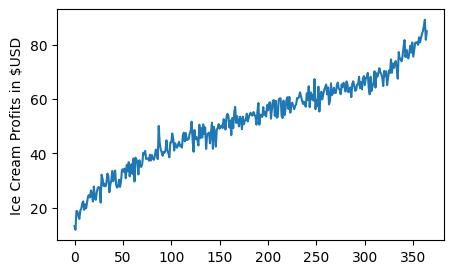

In [16]:
# 선 그래프
plt.plot(prof)   # 작성
plt.ylabel("Ice Cream Profits in $USD")
plt.show()

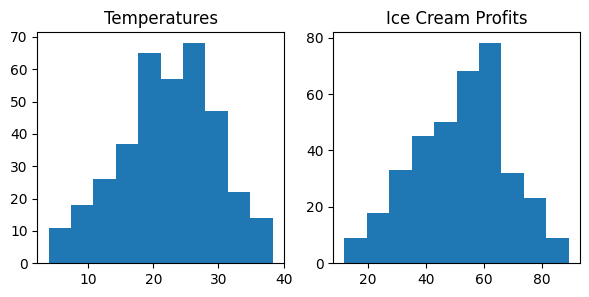

In [17]:
# 히스토그램
plt.figure(figsize=(7, 3))
plt.subplot(1,2,1)
plt.title("Temperatures")
plt.hist(temp_c)
plt.subplot(1,2,2)   # 작성
plt.title("Ice Cream Profits")
plt.hist(prof)   # 작성
plt.show()

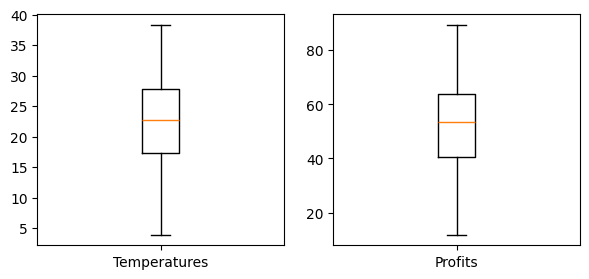

In [18]:
# 박스플롯
plt.figure(figsize=(7, 3))
plt.subplot(1,2,1)
plt.boxplot(temp_c)
plt.xticks([1], ["Temperatures"])
plt.subplot(1,2,2)
plt.boxplot(prof)
plt.xticks([1], ["Profits"])   # 작성
plt.show()

**산점도: 데이터 10개만 볼 때와 365개를 모두 볼 때**

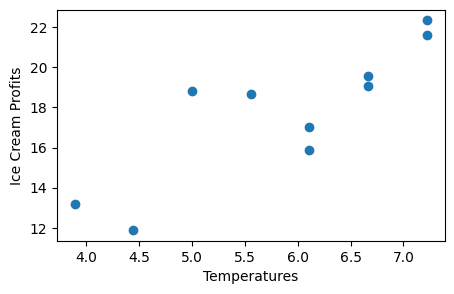

In [19]:
# 산점도, 앞의 10개 데이터만
plt.scatter(temp_c[:10], prof[:10])
plt.xlabel("Temperatures")
plt.ylabel("Ice Cream Profits")
plt.show()

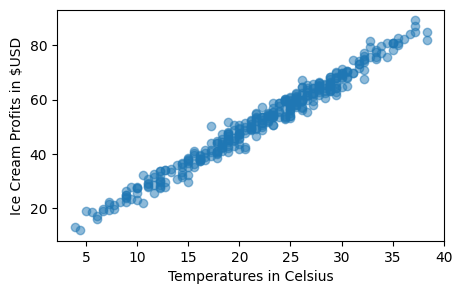

In [32]:
# 산점도, 전체 데이터, 점이 겹치므로 alpha로 반투명하게 그린다.
plt.scatter(temp_c, prof, alpha=0.5) # 작성
plt.xlabel("Temperatures in Celsius")
plt.ylabel("Ice Cream Profits in $USD")
plt.show()

- 데이터가 10개일 때는 두 변수 사이의 관계가 뚜렷하게 드러나지 않지만,
- 365개 전체 데이터를 살펴보면 기온이 높아질수록 수익이 증가하는 **직선 형태의 관계(선형 관계)**가 뚜렷하게 나타난다.
- 데이터가 많을수록 변수 사이의 관계나 숨겨진 패턴을 더 정확하고 신뢰성 있게 파악할 수 있다.
- 이것이 인공지능 학습에 많은 데이터가 필요한 이유 중 하나이다.

### 5. 예측 모델 만들기
예측선(y=ax, 예측 모델)

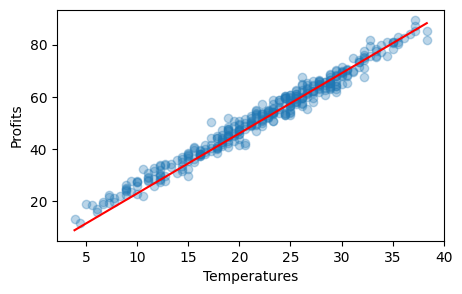

In [39]:
# ==========================
# 예측 함수 Ŷ = w * X
# ==========================
def pred_func(X, w):
    '''y=ax 모델에서 a는 가중치(w)이다.'''
    return w*X   # 작성

a = 2.3   #데이터를 잘 설명할 수 있는 a값을 찾아보자.   # 작성

X = data[:, 0]    # 작성
y = data[:, 1]    # 작성

# 정의된 모델 함수(pred_func)를 사용하여 예측값(y_pred) 계산
y_pred = pred_func(temp_c, a)    # 작성
#print(y_pred[:3])

#데이터 및 예측 모델 시각화
plt.scatter(temp_c, y, alpha=0.3)    # 작성
plt.plot(temp_c, y_pred, 'r')
plt.xlabel("Temperatures")
plt.ylabel("Profits")
plt.show()

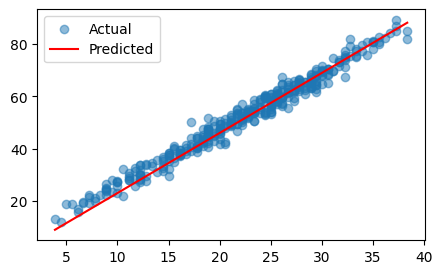

In [40]:
#범례를 추가해보자.
plt.scatter(temp_c, prof, alpha=0.5, label="Actual")
plt.plot(temp_c, y_pred, "r", label="Predicted")
plt.legend() # 작성
plt.show()